# Practical 08 – Decision Tree Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
raw = load_iris(as_frame=True)


In [2]:
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, average='macro'), 'Recall': recall_score(y_test, pred, average='macro'), 'F1': f1_score(y_test, pred, average='macro')}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=raw.target_names))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=raw.target_names, cmap='Blues')
    plt.title(name)
    plt.show()
    return scores


Decision Tree {'Accuracy': 0.9666666666666667, 'Precision': 0.9696969696969697, 'Recall': 0.9666666666666667, 'F1': 0.9665831244778612}
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



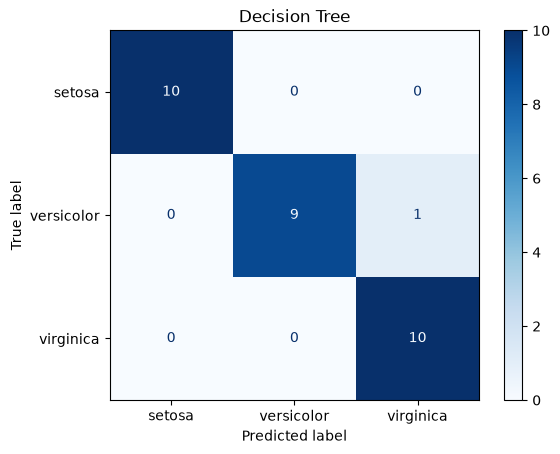

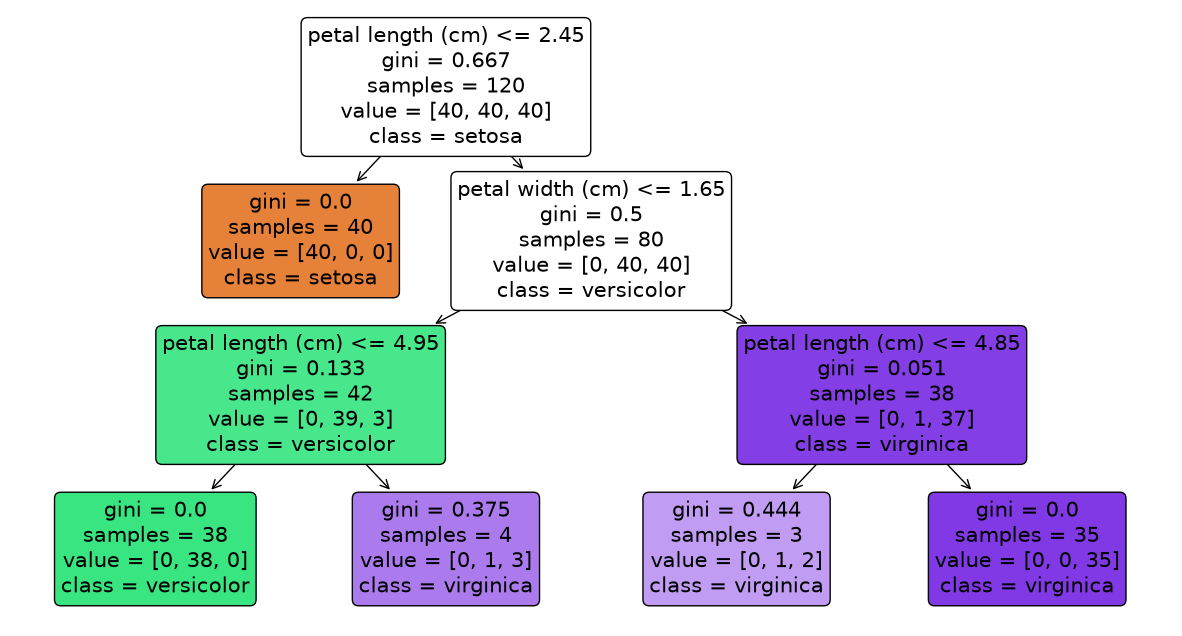

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
model = DecisionTreeClassifier(max_depth=3, random_state=42)
evaluate('Decision Tree', model)
plt.figure(figsize=(15, 8))
plot_tree(model, feature_names=list(X.columns), class_names=list(raw.target_names), filled=True, rounded=True)
plt.show()
